# Tugas 7: Geospatial Data Mining


**Nama/NIM : Putri Adria Garini (522500020)**


### **Pengantar:**

1. Mengunduh library terkait pengolahan data geospatial, seperti: geopandas, shapely, geopy untuk pengerjaan tugas lab ini.
2. Dataset yang digunakan adalah: jakarta_simplified_topo.json, Data Lokasi Halte.xlsx, dan Jumlah Penduduk Jakarta 2023.xlsx.
3. jakarta_simplified_topo.json -> dataset yang berisi data koordinat **lat** dan **long** peta Jakarta (di luar Kepulauan Seribu) dan batas wilayah-nya.
4. Data Lokasi Halte.xlsx -> dataset yang berisi data halte yang sering dikunjungi. Kolom yang tersedia:

| Kolom       | Deskripsi |
|-------------|-----------|
| **Nama Halte** | Nama halte yang sering dikunjungi. |
| **Rute** | Nomor atau kode rute yang melayani halte terkait. |
| **Tipe** | Tipe halte, terdiri dari "halte" atau "bus stop". |
| **Lokasi** | Kota di mana halte berlokasi. |
| **Lat** | Latitude halte. |
| **Long** | Longitude halte. |
| **In** | Kolom dengan tipe data binary. Nilai 1 menandakan halte tersebut menjadi lokasi di mana pengguna sering masuk / tap in. |
| **Out** | Kolom dengan tipe data binary. Nilai 1 menandakan halte tersebut menjadi lokasi di mana pengguna sering keluar / tap out. |
| **Transit** | Kolom dengan tipe data binary. Nilai 1 menandakan halte tersebut menjadi lokasi di mana pengguna sering melakukan transit ke rute lain. |


5. Jumlah Penduduk Jakarta 2023.xlsx -> dataset yang berisi jumlah penduduk Jakarta pada tahun 2023 berdasarkan Kabupaten / Kota. Kolom yang tersedia:

| Kolom            | Deskripsi |
|------------------|-----------|
| **KabKota**      | Nama kota administrasi Jakarta. |
| **Jumlah Penduduk** | Jumlah penduduk per kota administrasi pada tahun 2023. |


6. Dalam pengerjaan tugas ini saya menggunakan bantuan AI (Claude, Anthropic) untuk menyusun kode dan draf penjelasan analisis. Seluruh kode telah saya jalankan sendiri, hasilnya saya periksa, dan jawaban pada bagian 5c dan 5f telah saya sesuaikan dengan hasil visualisasi.

# Load and Transform Geospatial Data

1a. Import library yang diperlukan dan load data lokasi halte. (2)

In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from sklearn.metrics.pairwise import haversine_distances
from sklearn.cluster import AgglomerativeClustering

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

df = pd.read_excel("Data Lokasi Halte.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (99, 9)


,Nama Halte,Rute,Tipe,Lokasi,Lat,Long,In,Out,Transit
0,Blok M,1,Halte,Jakarta Selatan,-6.243500,106.800900,1,1,1
1,CSW,1,Halte,Jakarta Selatan,-6.239874,106.798413,1,1,1
2,Bundaran Senayan,1,Halte,Jakarta Selatan,-6.227400,106.801500,1,1,1
3,Gelora Bung Karno,1,Halte,Jakarta Selatan,-6.224200,106.805700,1,1,1
4,Polda Metro Jaya,1,Halte,Jakarta Selatan,-6.221400,106.809800,0,1,0


1b. Konversikan kolom Lat dan Long menjadi bentuk geometry dan buatlah format dataframe data lokasi halte menjadi geodataframe. (3)

Hint:
- Gunakan shapely - geometry
- Gunakan crs EPSG:4326 ketika menjadikan geodataframe.

In [3]:
geometry = [Point(xy) for xy in zip(df["Long"], df["Lat"])]   # Point(x=Long, y=Lat)
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")
print("CRS:", gdf.crs)
gdf.head()

CRS: EPSG:4326


,Nama Halte,Rute,Tipe,Lokasi,Lat,Long,In,Out,Transit,geometry
0,Blok M,1,Halte,Jakarta Selatan,-6.243500,106.800900,1,1,1,POINT (106.8009 -6.2435)
1,CSW,1,Halte,Jakarta Selatan,-6.239874,106.798413,1,1,1,POINT (106.79841 -6.23987)
2,Bundaran Senayan,1,Halte,Jakarta Selatan,-6.227400,106.801500,1,1,1,POINT (106.8015 -6.2274)
3,Gelora Bung Karno,1,Halte,Jakarta Selatan,-6.224200,106.805700,1,1,1,POINT (106.8057 -6.2242)
4,Polda Metro Jaya,1,Halte,Jakarta Selatan,-6.221400,106.809800,0,1,0,POINT (106.8098 -6.2214)


# Visualize Geospatial Data

2a. Load data provinsi Daerah Khusus Jakarta dan jumlah penduduk tahun 2023, kemudian visualisasikan peta berdasarkan jumlah penduduknya. (5)

,kabkot,Jumlah Penduduk
0,Jakarta Selatan,2235606
1,Jakarta Timur,3079618
2,Jakarta Pusat,1049314
3,Jakarta Barat,2470054
4,Jakarta Utara,1808985


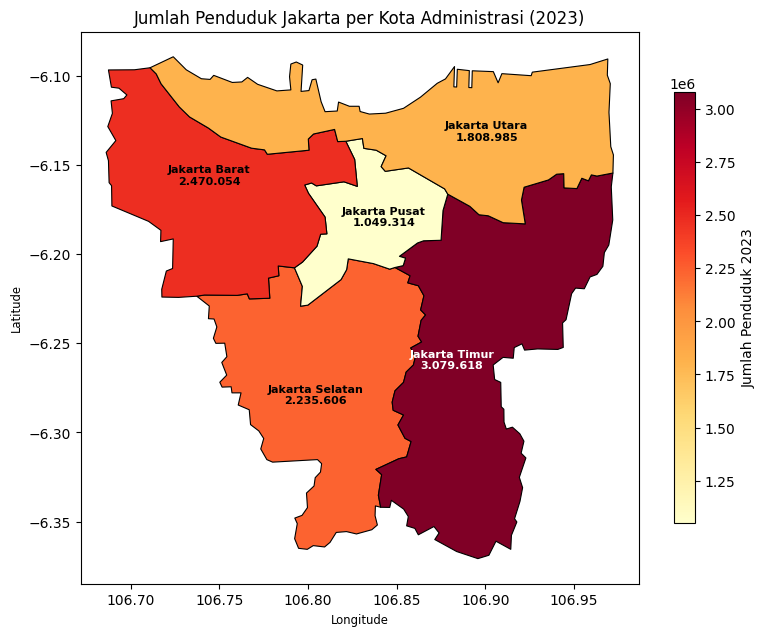

In [4]:
peta = gpd.read_file("jakarta-simplified-topo.json")
peta = peta.set_crs("EPSG:4326", allow_override=True)

import os
if os.path.exists("Jumlah Penduduk Jakarta 2023.csv"):
    pend = pd.read_csv("Jumlah Penduduk Jakarta 2023.csv", sep=";", encoding="utf-8-sig")
else:
    pend = pd.read_excel("Jumlah Penduduk Jakarta 2023.xlsx")
pend["KabKota"] = pend["KabKota"].str.strip()
peta = peta.merge(pend, left_on="kabkot", right_on="KabKota", how="left")
display(peta[["kabkot", "Jumlah Penduduk"]])

fig, ax = plt.subplots(figsize=(9, 8))
peta.plot(column="Jumlah Penduduk", cmap="YlOrRd", edgecolor="black", linewidth=0.8,
          legend=True, ax=ax, legend_kwds={"label": "Jumlah Penduduk 2023", "shrink": 0.7})
for _, r in peta.iterrows():
    c = r.geometry.representative_point()
    ax.annotate(f"{r['kabkot']}\n{r['Jumlah Penduduk']:,}".replace(",", "."),
                (c.x, c.y), ha="center", fontsize=8, weight="bold",
                color="white" if r["Jumlah Penduduk"] > 2.8e6 else "black")
ax.set_title("Jumlah Penduduk Jakarta per Kota Administrasi (2023)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

2b. Load data point lokasi halte, kemudian visualisasikan point (titik halte) bersamaan dengan peta Daerah Khusus Jakarta yang telah Anda load sebelumnya. (5)

Hint: lakukan overlay antara data peta Jakarta dengan titik lokasi halte.

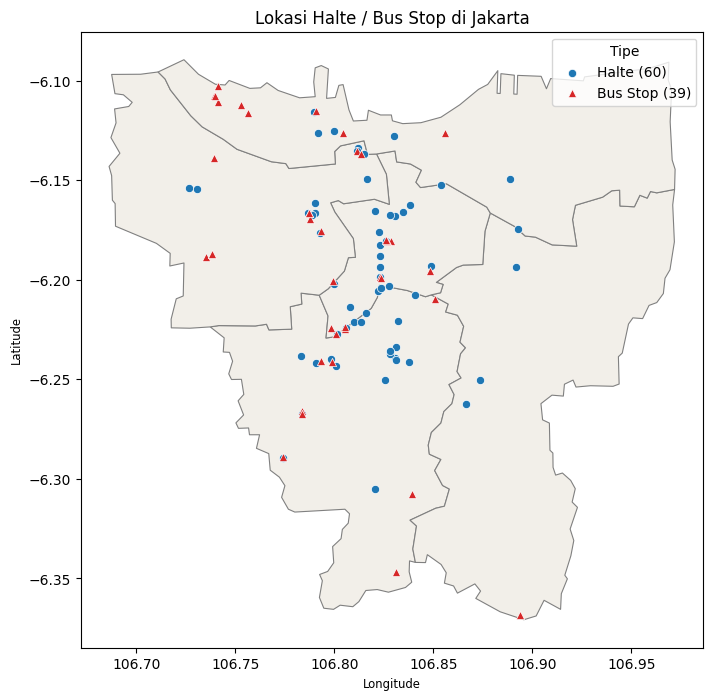

In [5]:
fig, ax = plt.subplots(figsize=(9, 8))
peta.plot(ax=ax, color="#f2efe9", edgecolor="gray", linewidth=0.8)
for tipe, warna, mk in [("Halte", "tab:blue", "o"), ("Bus Stop", "tab:red", "^")]:
    sub = gdf[gdf["Tipe"] == tipe]
    sub.plot(ax=ax, color=warna, marker=mk, markersize=35, edgecolor="white",
             linewidth=0.5, label=f"{tipe} ({len(sub)})")
ax.legend(title="Tipe")
ax.set_title("Lokasi Halte / Bus Stop di Jakarta")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

# Analyze Geospatial Data

3a. Sebuah minimarket ingin membuka gerai dan menargetkan pengguna Transjakarta. Salah satu penelitian yang pernah dilakukan adalah konsumen kerap berbelanja saat berada pada tujuan, sehingga tidak banyak membawa barang bawaan ke bus. Tunjukan lokasi **halte** yang menjadi target gerai tersebut akan dibuka. Visualisasikan dalam bentuk tabel dan peta. (10)

In [6]:
# Konsumen berbelanja di tujuan -> halte (bukan bus stop) tempat pengguna sering keluar (Out == 1)
target = gdf[(gdf["Tipe"] == "Halte") & (gdf["Out"] == 1)].copy()
print("Jumlah halte target:", len(target))
target.drop(columns="geometry").reset_index(drop=True)

Jumlah halte target: 39


,Nama Halte,Rute,Tipe,Lokasi,Lat,Long,In,Out,Transit
0,Blok M,1,Halte,Jakarta Selatan,-6.243500,106.800900,1,1,1
1,CSW,1,Halte,Jakarta Selatan,-6.239874,106.798413,1,1,1
2,Bundaran Senayan,1,Halte,Jakarta Selatan,-6.227400,106.801500,1,1,1
3,Gelora Bung Karno,1,Halte,Jakarta Selatan,-6.224200,106.805700,1,1,1
4,Polda Metro Jaya,1,Halte,Jakarta Selatan,-6.221400,106.809800,0,1,0
5,Tosari,1,Halte,Jakarta Pusat,-6.198600,106.823000,1,1,1
6,Bundaran HI,1,Halte,Jakarta Pusat,-6.193605,106.823016,0,1,0
7,MH Thamrin,1,Halte,Jakarta Pusat,-6.187970,106.822970,1,1,1
8,Monas,1,Halte,Jakarta Pusat,-6.176000,106.822800,0,1,1
9,Harmoni,1,Halte,Jakarta Pusat,-6.165600,106.820300,0,1,1


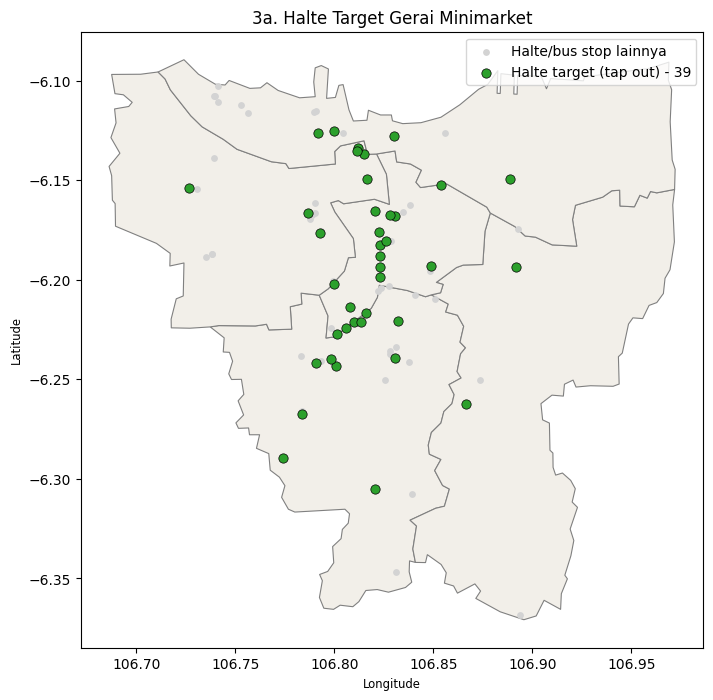

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))
peta.plot(ax=ax, color="#f2efe9", edgecolor="gray", linewidth=0.8)
gdf.plot(ax=ax, color="lightgray", markersize=15, label="Halte/bus stop lainnya")
target.plot(ax=ax, color="tab:green", markersize=45, edgecolor="black", linewidth=0.5,
            label=f"Halte target (tap out) - {len(target)}")
ax.legend(); ax.set_title("3a. Halte Target Gerai Minimarket")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

3b. Dari soal 3a, minimarket tersebut ingin membuka gerai yang radius nya maksimal 500 meter dari halte. Tunjukan wilayah atau zona sekitar halte yang memenuhi syarat tersebut. Visualisasikan dalam bentuk peta. (10)

Hint:
- Gunakan fungsi buffer dari geopandas.
- 500 meter dalam format EPSG:4326 = 0.0045

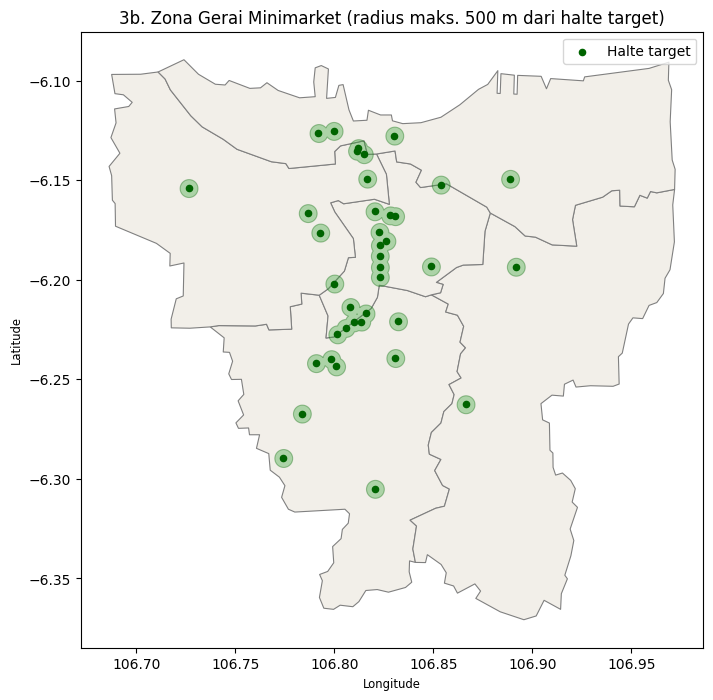

In [8]:
import warnings
zona = target.copy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # buffer di EPSG:4326 sesuai hint soal (0.0045 derajat ~ 500 m)
    zona["geometry"] = target.geometry.buffer(0.0045)
zona_gabungan = zona.geometry.union_all()

fig, ax = plt.subplots(figsize=(9, 8))
peta.plot(ax=ax, color="#f2efe9", edgecolor="gray", linewidth=0.8)
gpd.GeoSeries([zona_gabungan], crs="EPSG:4326").plot(ax=ax, color="tab:green", alpha=0.35,
                                                    edgecolor="darkgreen", linewidth=0.8)
target.plot(ax=ax, color="darkgreen", markersize=20, label="Halte target")
ax.legend(); ax.set_title("3b. Zona Gerai Minimarket (radius maks. 500 m dari halte target)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

# Haversine Distance

4a. Buatlah function haversine_distance yang akan menghasilkan nilai jarak haversine dalam satuan kilometer. (5)

Hint: gunakan library sklearn

### Penjelasan Haversine Distance

**Haversine formula** menghitung jarak terpendek antara dua titik pada permukaan bola (*great-circle distance*) berdasarkan koordinat lintang (*latitude*) dan bujur (*longitude*). Karena bumi berbentuk (mendekati) bola, jarak Euclidean pada koordinat derajat kurang tepat, terutama untuk jarak yang jauh.

**Rumus**, untuk dua titik $(\varphi_1, \lambda_1)$ dan $(\varphi_2, \lambda_2)$ dalam radian:

$$a = \sin^2\left(\frac{\varphi_2-\varphi_1}{2}\right) + \cos(\varphi_1)\,\cos(\varphi_2)\,\sin^2\left(\frac{\lambda_2-\lambda_1}{2}\right)$$

$$d = 2R\,\arcsin\left(\sqrt{a}\right)$$

| Simbol | Keterangan |
|---|---|
| $d$ | jarak *great-circle* antara dua titik (km) |
| $R$ | jari-jari bumi, $\approx$ 6371 km |
| $\varphi_1, \varphi_2$ | latitude titik 1 dan 2 (radian) |
| $\lambda_1, \lambda_2$ | longitude titik 1 dan 2 (radian) |
| $a$ | haversine dari sudut pusat antara kedua titik |

**Cara kerja:** rumus mencari sudut pusat $\theta$ antara dua titik terhadap pusat bumi, lalu mengubahnya menjadi jarak permukaan dengan $d = R\,\theta$. Di sini $\theta = 2\arcsin(\sqrt{a})$.

**Contoh pada data:** Halte Blok M $(-6{,}2435;\ 106{,}8009)$ ke CSW $(-6{,}239874;\ 106{,}798413)$:
- $a \approx 1{,}467 \times 10^{-9}$
- $\theta = 2\arcsin(\sqrt{a}) \approx 7{,}66 \times 10^{-5}$ rad
- $d = R\,\theta = 6371{,}0088 \times 7{,}66 \times 10^{-5} \approx 0{,}49$ km, sama dengan keluaran fungsi di bawah.

**Pada kode:** `haversine_distances` dari scikit-learn menghasilkan nilai sudut $\theta$ (dalam radian), sehingga dikalikan $R$ = 6371,0088 km untuk mendapatkan jarak dalam kilometer. Input harus berurutan `[latitude, longitude]` dan sudah dalam radian (`np.radians`).

**Kegunaan:** menghitung jarak antar koordinat pada navigasi, penerbangan, dan GIS. Pada tugas ini dipakai untuk matriks jarak antar halte (4b), mencari jarak terjauh (4c), dan sebagai ukuran jarak pada *Agglomerative Clustering* (5a, 5d).

In [9]:
R_BUMI = 6371.0088  # km

def haversine_distance(lat1, lon1, lat2, lon2):
    """Jarak haversine (km) antara dua titik (dalam derajat)."""
    a = np.radians([[lat1, lon1]])
    b = np.radians([[lat2, lon2]])
    return haversine_distances(a, b)[0, 0] * R_BUMI

# contoh: Blok M -> CSW
print(round(haversine_distance(df.at[0,"Lat"], df.at[0,"Long"], df.at[1,"Lat"], df.at[1,"Long"]), 2), "km")

0.49 km


4b. Hitung jarak antar halte atau bus stop dengan menggunakan function yang telah Anda buat, tampilkan dalam bentuk matriks jarak. (5)

In [10]:
n = len(df)
nama = df["Nama Halte"].tolist()
mat = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        mat[i, j] = mat[j, i] = haversine_distance(df.at[i, "Lat"], df.at[i, "Long"],
                                                   df.at[j, "Lat"], df.at[j, "Long"])
# beri akhiran indeks pada nama yang kembar agar label unik
label = [f"{k}_{i}" if nama.count(k) > 1 else k for i, k in enumerate(nama)]
matriks = pd.DataFrame(mat, index=label, columns=label)
matriks.round(2)

,Blok M,CSW,Bundaran Senayan,Gelora Bung Karno,Polda Metro Jaya,Dukuh Atas,Tosari,Bundaran HI,MH Thamrin,Monas,Harmoni,Olimo,Kota,Kebon Sirih,Pulomas,...,Sunter Boulevard Barat,Jln. Gelong Baru Utara,Metro Pondok Indah,M Bloc,Pondok Indah 3,Mampang Prapatan,Simpang Kuningan,Underpass Kuningan,Simpang Mandara Permai 2,Sentraland Cengkareng,RS PIK 1,Semanggi,Jalan Puri Harum,Jembatan Baru,Bendungan Hilir
Blok M,0.00,0.49,1.79,2.21,2.65,4.83,5.56,6.06,6.64,7.89,8.92,10.63,11.95,7.19,12.71,...,14.29,7.59,3.15,0.34,3.26,2.85,3.08,3.13,14.99,13.47,15.54,2.87,9.35,12.58,3.38
CSW,0.49,0.00,1.43,1.92,2.41,4.63,5.33,5.82,6.38,7.60,8.61,10.28,11.59,6.91,12.70,...,14.18,7.16,3.33,0.17,3.46,3.24,3.29,3.32,14.52,12.98,15.07,2.69,8.88,12.09,3.19
Bundaran Senayan,1.79,1.43,0.00,0.58,1.13,3.33,3.99,4.45,4.99,6.18,7.18,8.85,10.17,5.51,11.66,...,12.98,5.83,4.72,1.59,4.86,3.71,3.13,3.09,13.33,12.00,13.90,1.52,8.31,11.27,1.96
Gelora Bung Karno,2.21,1.92,0.58,0.00,0.55,2.76,3.43,3.90,4.46,5.68,6.71,8.43,9.76,5.00,11.08,...,12.40,5.57,5.25,2.07,5.38,3.67,2.87,2.80,13.19,11.99,13.76,0.94,8.53,11.36,1.38
Polda Metro Jaya,2.65,2.41,1.13,0.55,0.00,2.23,2.93,3.42,3.99,5.25,6.31,8.06,9.41,4.54,10.54,...,11.85,5.41,5.74,2.55,5.86,3.68,2.68,2.59,13.11,12.03,13.68,0.42,8.79,11.49,0.83
Dukuh Atas,4.83,4.63,3.33,2.76,2.23,0.00,0.78,1.34,1.96,3.29,4.45,6.30,7.68,2.55,8.52,...,9.66,4.63,7.96,4.76,8.07,5.01,3.58,3.43,12.32,11.78,12.91,1.96,9.52,11.62,1.44
Tosari,5.56,5.33,3.99,3.43,2.93,0.78,0.00,0.56,1.18,2.51,3.68,5.54,6.92,1.77,8.15,...,9.11,4.17,8.67,5.47,8.79,5.78,4.34,4.18,11.76,11.38,12.35,2.70,9.47,11.34,2.19
Bundaran HI,6.06,5.82,4.45,3.90,3.42,1.34,0.56,0.00,0.63,1.96,3.13,4.99,6.37,1.21,7.99,...,8.78,3.86,9.15,5.96,9.28,6.33,4.89,4.73,11.34,11.06,11.92,3.22,9.41,11.11,2.71
MH Thamrin,6.64,6.38,4.99,4.46,3.99,1.96,1.18,0.63,0.00,1.33,2.50,4.37,5.75,0.59,7.85,...,8.45,3.57,9.71,6.52,9.83,6.96,5.51,5.35,10.86,10.73,11.45,3.82,9.38,10.88,3.31
Monas,7.89,7.60,6.18,5.68,5.25,3.29,2.51,1.96,1.33,0.00,1.19,3.06,4.43,0.75,7.73,...,7.88,3.28,10.90,7.75,11.04,8.29,6.84,6.68,9.91,10.10,10.50,5.11,9.45,10.48,4.61


4c. Jika ingin menempuh jarak terjauh, sebutkan halte/bus stop keberangkatan dan halte/bus stop tujuan yang dapat dicapai, beserta dengan jaraknya dalam kilometer (bulatkan 2 angka di belakang koma). Anda tidak perlu mempertimbangkan rute atau jalan yang ditempuh, hanya mempertimbangkan jarak antar halte (jarak haversine). (5)

In [11]:
i, j = np.unravel_index(np.argmax(mat), mat.shape)
print(f"Keberangkatan : {df.at[i,'Nama Halte']} ({df.at[i,'Tipe']}, rute {df.at[i,'Rute']}, {df.at[i,'Lokasi']})")
print(f"Tujuan        : {df.at[j,'Nama Halte']} ({df.at[j,'Tipe']}, rute {df.at[j,'Rute']}, {df.at[j,'Lokasi']})")
print(f"Jarak terjauh : {mat[i, j]:.2f} km")

Keberangkatan : Cibubur Junction (Bus Stop, rute 7C, Jakarta Timur)
Tujuan        : Fresh Market PIK (Bus Stop, rute 1A, Jakarta Utara)
Jarak terjauh : 34.02 km


# Clustering

5a. Lakukan pengelompokan untuk zonasi wilayah dari halte yang sering dikunjungi. Gunakan algoritma Agglomerative Clustering dengan jumlah cluster = 4 dan menggunakan jarak Haversine. Kemudian tampilkan Nama Halte, Rute, Tipe, Lokasi, Lat, Long, In, Out, Transit, Geometry, dan Cluster dalam bentuk dataframe. (10)

Hint:
- Gunakan average linkage.
- Data yang digunakan untuk clustering adalah data lengkap saat pertama kali Anda load dataset "Data Lokasi Halte.xlsx"
- Gunakan fitur **Lat** dan **Long** untuk clustering.

In [12]:
# Agglomerative clustering, average linkage, jarak haversine (matriks jarak dalam radian, precomputed)
coords_rad = np.radians(df[["Lat", "Long"]].values)
dist_hav = haversine_distances(coords_rad)

def klaster(k):
    model = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average")
    out = gdf.copy()
    out["Cluster"] = model.fit_predict(dist_hav)
    return out

kolom = ["Nama Halte", "Rute", "Tipe", "Lokasi", "Lat", "Long", "In", "Out", "Transit", "geometry", "Cluster"]
g4 = klaster(4)

In [13]:
g4[kolom]

,Nama Halte,Rute,Tipe,Lokasi,Lat,Long,In,Out,Transit,geometry,Cluster
0,Blok M,1,Halte,Jakarta Selatan,-6.243500,106.800900,1,1,1,POINT (106.8009 -6.2435),0
1,CSW,1,Halte,Jakarta Selatan,-6.239874,106.798413,1,1,1,POINT (106.79841 -6.23987),0
2,Bundaran Senayan,1,Halte,Jakarta Selatan,-6.227400,106.801500,1,1,1,POINT (106.8015 -6.2274),0
3,Gelora Bung Karno,1,Halte,Jakarta Selatan,-6.224200,106.805700,1,1,1,POINT (106.8057 -6.2242),0
4,Polda Metro Jaya,1,Halte,Jakarta Selatan,-6.221400,106.809800,0,1,0,POINT (106.8098 -6.2214),0
5,Dukuh Atas,1,Halte,Jakarta Selatan,-6.205600,106.822200,1,0,1,POINT (106.8222 -6.2056),0
6,Tosari,1,Halte,Jakarta Pusat,-6.198600,106.823000,1,1,1,POINT (106.823 -6.1986),0
7,Bundaran HI,1,Halte,Jakarta Pusat,-6.193605,106.823016,0,1,0,POINT (106.82302 -6.1936),0
8,MH Thamrin,1,Halte,Jakarta Pusat,-6.187970,106.822970,1,1,1,POINT (106.82297 -6.18797),0
9,Monas,1,Halte,Jakarta Pusat,-6.176000,106.822800,0,1,1,POINT (106.8228 -6.176),0


5b. Visualisasikan peta dan titik hasil clustering dengan peta Daerah Khusus Jakarta, bedakan warna titik berdasarkan cluster (untuk 4 cluster). (10)

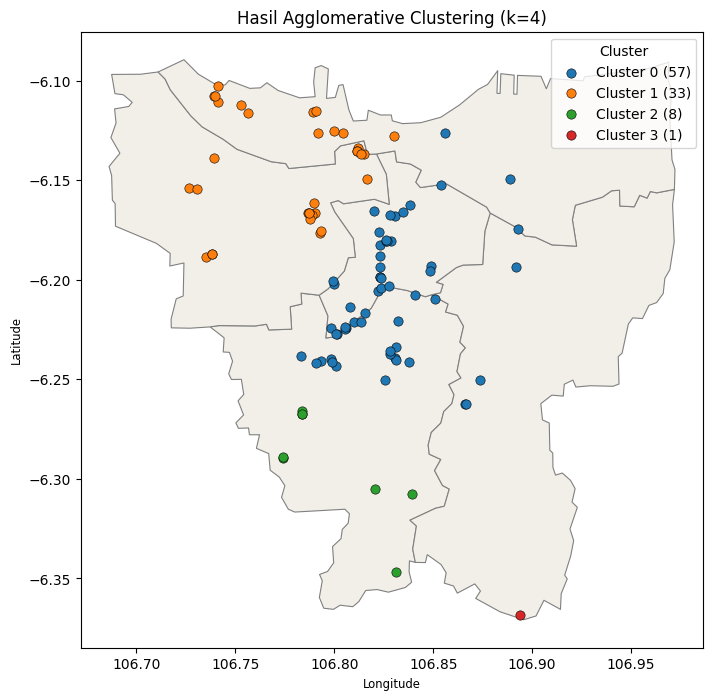

In [14]:
def plot_klaster(hasil, k):
    fig, ax = plt.subplots(figsize=(9, 8))
    peta.plot(ax=ax, color="#f2efe9", edgecolor="gray", linewidth=0.8)
    cmap = plt.get_cmap("tab10")
    for c in sorted(hasil["Cluster"].unique()):
        hasil[hasil["Cluster"] == c].plot(ax=ax, color=cmap(c), markersize=45, edgecolor="black",
                                          linewidth=0.4, label=f"Cluster {c} ({(hasil['Cluster']==c).sum()})")
    ax.legend(title="Cluster"); ax.set_title(f"Hasil Agglomerative Clustering (k={k})")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    plt.show()

plot_klaster(g4, 4)

**Jawaban 5c (k = 4)**

Dengan k = 4, halte terbagi menjadi empat kelompok berdasarkan kedekatan geografis:

- **Cluster 0 (57 halte), Jakarta bagian tengah dan inti kota.** Cluster terbesar, membentang dari utara ke selatan sepanjang koridor utama: Blok M, CSW, Senayan, GBK, Dukuh Atas, Bundaran HI, Thamrin, Monas, Harmoni, Kuningan, Mampang, sampai Manggarai. Mayoritas halte berada di Jakarta Pusat dan Jakarta Selatan. Di cluster ini juga ikut sebagian halte di timur laut dan timur (Pulomas, Rawamangun, Sunter, Kemayoran, JIS) serta Cawang, PGC, dan Cililitan, karena dengan hanya 4 cluster titik-titik ini paling dekat ke kelompok pusat.
- **Cluster 1 (33 halte), Jakarta Barat dan Jakarta Utara bagian barat.** Mencakup Kota Tua (Kota, Museum Fatahillah, Kali Besar), Grogol, Jelambar, Tanjung Duren, Rawa Buaya, Pluit, Penjaringan, Ancol, serta kawasan PIK dan Puri Kembangan di pesisir barat laut.
- **Cluster 2 (8 halte), Jakarta Selatan bagian selatan.** Mencakup Lebak Bulus, Pondok Indah, Ragunan, Tanjung Barat, dan Universitas Indonesia. Kelompok ini terpisah dari inti kota karena jaraknya cukup jauh di selatan.
- **Cluster 3 (1 halte), Cibubur Junction.** Satu-satunya titik di ujung tenggara Jakarta Timur. Halte ini adalah outlier karena letaknya sangat jauh dari halte lain, sehingga baru bergabung ke kelompok lain pada tahap terakhir penggabungan average linkage.

5d. Lakukan pengelompokan untuk zonasi wilayah dari halte yang sering dikunjungi. Gunakan algoritma Agglomerative Clustering dengan jumlah cluster = 6 dan meggunakan jarak Haversine. Kemudian tampilkan Nama Halte, Rute, Tipe, Lokasi, Lat, Long, In, Out, Transit, Geometry, dan Cluster dalam bentuk dataframe. (10)

Hint:
- Gunakan average linkage,
- Data yang digunakan untuk clustering adalah data lengkap saat pertama kali Anda load dataset "Data Lokasi Halte.xlsx"
- Gunakan fitur **Lat** dan **Long** untuk clustering.

In [15]:
g6 = klaster(6)
g6[kolom]

,Nama Halte,Rute,Tipe,Lokasi,Lat,Long,In,Out,Transit,geometry,Cluster
0,Blok M,1,Halte,Jakarta Selatan,-6.243500,106.800900,1,1,1,POINT (106.8009 -6.2435),4
1,CSW,1,Halte,Jakarta Selatan,-6.239874,106.798413,1,1,1,POINT (106.79841 -6.23987),4
2,Bundaran Senayan,1,Halte,Jakarta Selatan,-6.227400,106.801500,1,1,1,POINT (106.8015 -6.2274),4
3,Gelora Bung Karno,1,Halte,Jakarta Selatan,-6.224200,106.805700,1,1,1,POINT (106.8057 -6.2242),4
4,Polda Metro Jaya,1,Halte,Jakarta Selatan,-6.221400,106.809800,0,1,0,POINT (106.8098 -6.2214),4
5,Dukuh Atas,1,Halte,Jakarta Selatan,-6.205600,106.822200,1,0,1,POINT (106.8222 -6.2056),4
6,Tosari,1,Halte,Jakarta Pusat,-6.198600,106.823000,1,1,1,POINT (106.823 -6.1986),4
7,Bundaran HI,1,Halte,Jakarta Pusat,-6.193605,106.823016,0,1,0,POINT (106.82302 -6.1936),4
8,MH Thamrin,1,Halte,Jakarta Pusat,-6.187970,106.822970,1,1,1,POINT (106.82297 -6.18797),4
9,Monas,1,Halte,Jakarta Pusat,-6.176000,106.822800,0,1,1,POINT (106.8228 -6.176),4


5e. Visualisasikan peta dan titik hasil clustering dengan peta Daerah Khusus Jakarta, bedakan warna titik berdasarkan cluster (untuk 6 cluster). (10)

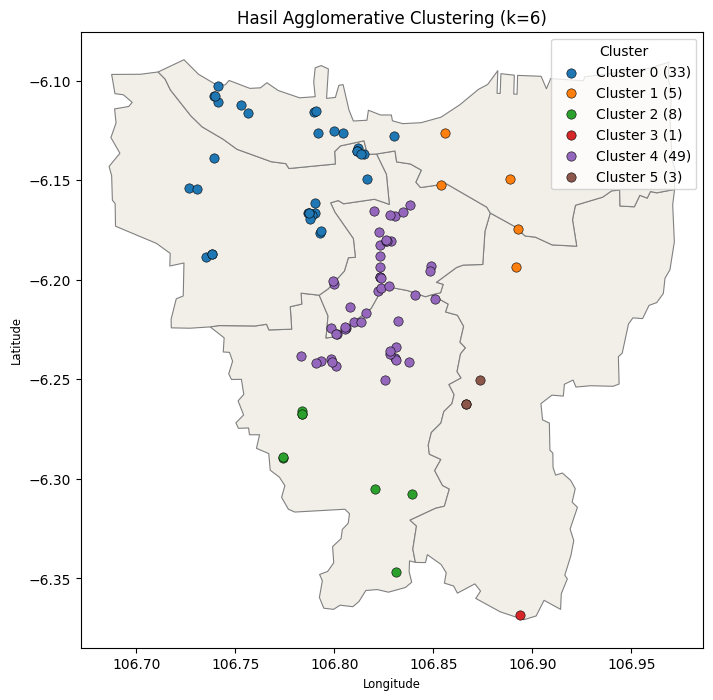

In [16]:
plot_klaster(g6, 6)

**Jawaban 5f (k = 6)**

Dengan k = 6, cluster besar pada k = 4 (cluster tengah) terpecah, sedangkan cluster barat-utara, selatan, dan Cibubur tidak berubah. Hasilnya:

- **Cluster 4 (49 halte), inti Jakarta Pusat dan Jakarta Selatan.** Koridor utama dari Blok M, Senayan, Sudirman-Thamrin, Monas, Harmoni, Kuningan, sampai Manggarai dan Salemba. Ini kelompok halte terpadat dan paling sering menjadi tempat transit.
- **Cluster 0 (33 halte), Jakarta Barat dan Jakarta Utara bagian barat.** Mencakup Kota Tua, Grogol, Jelambar, Tanjung Duren, Rawa Buaya, Pluit, Penjaringan, Ancol, PIK, dan Puri Kembangan.
- **Cluster 2 (8 halte), Jakarta Selatan bagian selatan.** Mencakup Lebak Bulus, Pondok Indah, Ragunan, Tanjung Barat, dan UI.
- **Cluster 1 (5 halte), kawasan timur laut.** Mencakup Pulomas, Pemuda Rawamangun, Sunter Boulevard Barat, Kemayoran Landas Pacu Timur, dan JIS. Titiknya tersebar di perbatasan Jakarta Utara dan Jakarta Timur.
- **Cluster 5 (3 halte), kawasan Cawang-Cililitan.** Terdiri dari Cawang Sentral, PGC, dan Cililitan di Jakarta Timur bagian tengah. Halte ini berdekatan satu sama lain dan cukup jauh dari inti kota.
- **Cluster 3 (1 halte), Cibubur Junction.** Tetap menjadi outlier di ujung tenggara Jakarta Timur.

Perbedaan dengan k = 4: kawasan timur laut dan Cawang-Cililitan, yang sebelumnya ikut ke cluster tengah, kini membentuk kelompok sendiri. Itu menunjukkan halte di Jakarta Timur dan Utara bagian timur letaknya memang terpisah dari koridor utama kota.

In [17]:
def ringkas(hasil):
    rows = []
    for c in sorted(hasil["Cluster"].unique()):
        s = hasil[hasil["Cluster"] == c]
        rows.append({"Cluster": c, "Jumlah": len(s),
                     "Lat (min..max)": f"{s.Lat.min():.3f} .. {s.Lat.max():.3f}",
                     "Long (min..max)": f"{s.Long.min():.3f} .. {s.Long.max():.3f}",
                     "Lokasi": s["Lokasi"].value_counts().to_dict(),
                     "Contoh halte": ", ".join(s["Nama Halte"].head(6))})
    return pd.DataFrame(rows)

print("Ringkasan k=4"); display(ringkas(g4))
print("Ringkasan k=6"); display(ringkas(g6))

Ringkasan k=4


,Cluster,Jumlah,Lat (min..max),Long (min..max),Lokasi,Contoh halte
0,0,57,-6.263 .. -6.126,106.783 .. 106.893,"{'Jakarta Pusat': 26, 'Jakarta Selatan': 22, '...","Blok M, CSW, Bundaran Senayan, Gelora Bung Kar..."
1,1,33,-6.189 .. -6.103,106.726 .. 106.830,"{'Jakarta Barat': 21, 'Jakarta Utara': 12}","Olimo, Kota, Rawa Buaya, Jelambar, Grogol 1, A..."
2,2,8,-6.347 .. -6.266,106.774 .. 106.839,{'Jakarta Selatan': 8},"Ragunan, Lebak Bulus, Pondok Indah 2, Universi..."
3,3,1,-6.369 .. -6.369,106.894 .. 106.894,{'Jakarta Timur': 1},Cibubur Junction


Ringkasan k=6


,Cluster,Jumlah,Lat (min..max),Long (min..max),Lokasi,Contoh halte
0,0,33,-6.189 .. -6.103,106.726 .. 106.830,"{'Jakarta Barat': 21, 'Jakarta Utara': 12}","Olimo, Kota, Rawa Buaya, Jelambar, Grogol 1, A..."
1,1,5,-6.193 .. -6.126,106.854 .. 106.893,"{'Jakarta Utara': 4, 'Jakarta Timur': 1}","Pulomas, Pemuda Rawamangun, Kemayoran Landas P..."
2,2,8,-6.347 .. -6.266,106.774 .. 106.839,{'Jakarta Selatan': 8},"Ragunan, Lebak Bulus, Pondok Indah 2, Universi..."
3,3,1,-6.369 .. -6.369,106.894 .. 106.894,{'Jakarta Timur': 1},Cibubur Junction
4,4,49,-6.251 .. -6.162,106.783 .. 106.851,"{'Jakarta Pusat': 26, 'Jakarta Selatan': 22, '...","Blok M, CSW, Bundaran Senayan, Gelora Bung Kar..."
5,5,3,-6.263 .. -6.250,106.866 .. 106.874,{'Jakarta Timur': 3},"Cawang Sentral, PGC, Cililitan"
